# Visualising the KKT conditions

This notebook trains `KKTSVM` on a small 2-D dataset and makes the figures used in the README:

1. the decision boundary, with support vectors marked by the KKT case they fall in;
2. the complementary-slackness diagram: every point plotted at $(y_i f(x_i),\ \alpha_i / C)$;
3. how the KKT gap shrinks during training;
4. the multipliers $\alpha_i$ checked against finite-difference shadow prices.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.preprocessing import StandardScaler

from svm_kkt import KKTSVM, kkt_report, shadow_prices, smo

BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 9,
})

## Train the model and check the KKT conditions

In [2]:
X, y = make_moons(150, noise=0.25, random_state=7)
model = KKTSVM(C=3.0, kernel="rbf", gamma=2.0).fit(X, y)
report = kkt_report(model, X, y)

print(f"SMO iterations: {model.n_iter_}, training accuracy: {model.score(X, y):.3f}")
print(f"not support vectors (alpha = 0):   {report['n_non_sv']}")
print(f"margin support vectors (0<alpha<C): {report['n_margin_sv']}")
print(f"bound support vectors (alpha = C):  {report['n_bound_sv']}")
print()
print(f"stationarity     |sum alpha_i y_i| = {abs(report['sum_alpha_y']):.1e}")
print(f"dual feasibility  box violation    = {report['box_violation']:.1e}")
print(f"compl. slackness  max violation    = {report['max_violation']:.1e}  (tol = {model.tol})")
print(f"duality gap       P - D            = {report['duality_gap']:.1e}  (P = {report['primal']:.4f})")

SMO iterations: 190, training accuracy: 0.940
not support vectors (alpha = 0):   108
margin support vectors (0<alpha<C): 17
bound support vectors (alpha = C):  25

stationarity     |sum alpha_i y_i| = 1.8e-15
dual feasibility  box violation    = 0.0e+00
compl. slackness  max violation    = 5.0e-04  (tol = 0.001)
duality gap       P - D            = 3.7e-03  (P = 78.8255)


## Support vectors and complementary slackness

Colour shows the class. A ring marks a **margin** support vector ($0<\alpha_i<C$, exactly on the margin);
a square marks a **bound** support vector ($\alpha_i=C$, inside the margin or misclassified).
On the right, complementary slackness only allows three places for a point, which together form
the Z-shaped grey path.

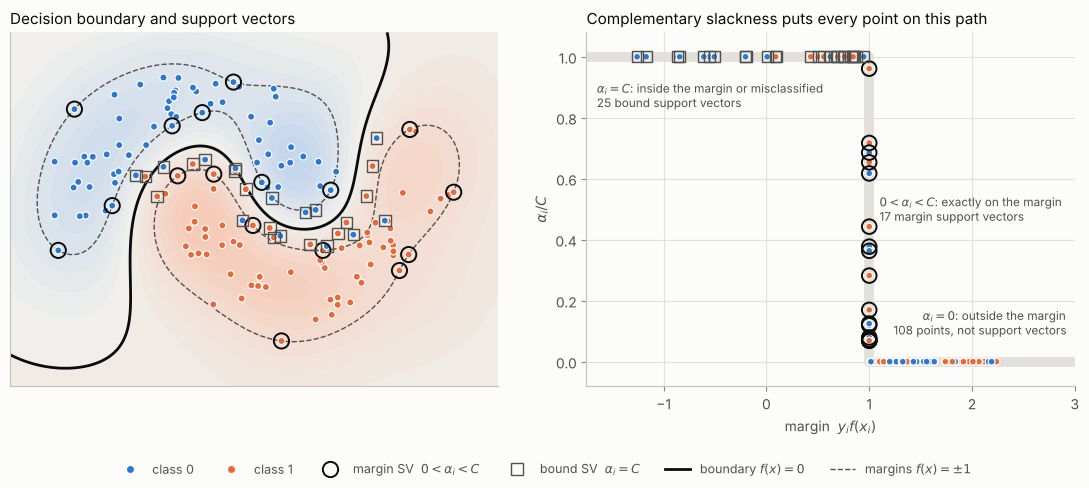

In [3]:
def draw_points(ax, px, py, size=26):
    colour = np.where(y == model.classes_[1], ORANGE, BLUE)
    ax.scatter(px, py, s=size, c=colour, edgecolors=SURFACE, linewidths=0.9, zorder=3)
    m, b = model.margin_support_, model.bound_support_
    ax.scatter(px[m], py[m], s=size * 4.6, facecolors="none", edgecolors=INK, linewidths=1.4, zorder=4)
    ax.scatter(px[b], py[b], s=size * 2.7, marker="s", facecolors="none", edgecolors=INK2, linewidths=1.0, zorder=4)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.9))

# left: decision regions, boundary f = 0 and margins f = +-1
gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - .4, X[:, 0].max() + .4, 300),
                     np.linspace(X[:, 1].min() - .4, X[:, 1].max() + .4, 300))
f = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
ax1.contourf(gx, gy, np.clip(f, -2.5, 2.5), levels=21,
             cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("", ["#bdd3ec", "#f0efec", "#f6c9b5"]))
ax1.contour(gx, gy, f, levels=[0], colors=INK, linewidths=2)
ax1.contour(gx, gy, f, levels=[-1, 1], colors=INK2, linewidths=1, linestyles="--")
draw_points(ax1, X[:, 0], X[:, 1])
ax1.set(xticks=[], yticks=[], title="Decision boundary and support vectors")
ax1.grid(False)

# right: every point at (y_i f(x_i), alpha_i / C)
margins, a = report["margins"], model.alpha_ / model.C
ax2.plot([-1.75, 1, 1, 3], [1, 1, 0, 0], color=GRID, lw=7, solid_capstyle="round", zorder=1)
draw_points(ax2, margins, a, size=24)
ax2.text(-1.65, 0.92, f"$\\alpha_i=C$: inside the margin or misclassified\n{report['n_bound_sv']} bound support vectors",
         color=INK2, fontsize=8.5, va="top")
ax2.text(1.1, 0.5, f"$0<\\alpha_i<C$: exactly on the margin\n{report['n_margin_sv']} margin support vectors",
         color=INK2, fontsize=8.5, va="center")
ax2.text(2.92, 0.08, f"$\\alpha_i=0$: outside the margin\n{report['n_non_sv']} points, not support vectors",
         color=INK2, fontsize=8.5, ha="right", va="bottom")
ax2.set(xlim=(-1.75, 3), ylim=(-0.08, 1.08), xlabel="margin  $y_i f(x_i)$", ylabel="$\\alpha_i / C$",
        title="Complementary slackness puts every point on this path")

handles = [
    Line2D([], [], marker="o", ls="none", color=BLUE, mec=SURFACE, ms=6, label="class 0"),
    Line2D([], [], marker="o", ls="none", color=ORANGE, mec=SURFACE, ms=6, label="class 1"),
    Line2D([], [], marker="o", ls="none", mfc="none", mec=INK, mew=1.4, ms=11, label="margin SV  $0<\\alpha_i<C$"),
    Line2D([], [], marker="s", ls="none", mfc="none", mec=INK2, ms=9, label="bound SV  $\\alpha_i=C$"),
    Line2D([], [], color=INK, lw=2, label="boundary $f(x)=0$"),
    Line2D([], [], color=INK2, lw=1, ls="--", label="margins $f(x)=\\pm1$"),
]
fig.tight_layout(w_pad=2.5, rect=(0, 0.07, 1, 1))
fig.legend(handles=handles, loc="lower center", ncol=6, labelcolor=INK2)
fig.savefig("../figures/kkt_svm.png", dpi=160)

## The KKT gap during training

Each SMO step updates the pair of multipliers that violate the KKT conditions most. The gap
$m(\alpha)-M(\alpha)$ is not monotone (fixing one pair can upset another), but the dual objective rises at
every step, and training stops once the gap falls below `tol`.

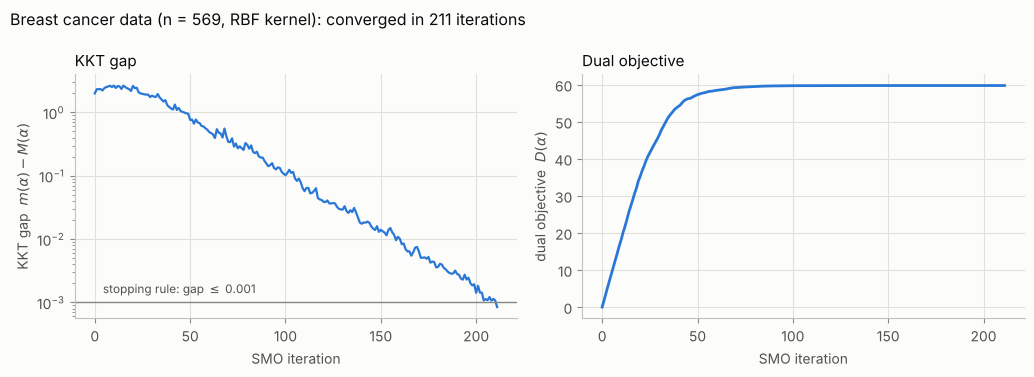

In [4]:
Xc, yc = load_breast_cancer(return_X_y=True)
Xc = StandardScaler().fit_transform(Xc)
run = KKTSVM(C=1.0, tol=1e-3).fit(Xc, yc)
gap, dual = run.history_["kkt_gap"], run.history_["dual_objective"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 3.8))
ax1.semilogy(gap, color=BLUE, lw=1.6)
ax1.axhline(run.tol, color=MUTED, lw=1)
ax1.text(len(gap) * 0.02, run.tol * 1.4, f"stopping rule: gap $\\leq$ {run.tol:g}", color=INK2, fontsize=8.5)
ax1.set(xlabel="SMO iteration", ylabel="KKT gap  $m(\\alpha)-M(\\alpha)$", title="KKT gap")
ax2.plot(dual, color=BLUE, lw=2)
ax2.set(xlabel="SMO iteration", ylabel="dual objective  $D(\\alpha)$", title="Dual objective")
fig.suptitle(f"Breast cancer data (n = {len(yc)}, RBF kernel): converged in {run.n_iter_} iterations",
             x=0.01, ha="left", fontsize=11.5, color=INK)
fig.tight_layout()
fig.savefig("../figures/convergence.png", dpi=160)

## Multipliers are shadow prices

Require point $i$ to reach margin $r_i$ instead of 1, and let $V^\star(r)$ be the optimal objective.
The envelope theorem says $\partial V^\star / \partial r_i = \alpha_i$. `shadow_prices` re-solves the SVM with
each $r_i$ nudged by $\pm h$ and compares the finite difference with the solver's $\alpha_i$.

max |alpha_i - dV/dr_i| over 150 points: 1.5e-09


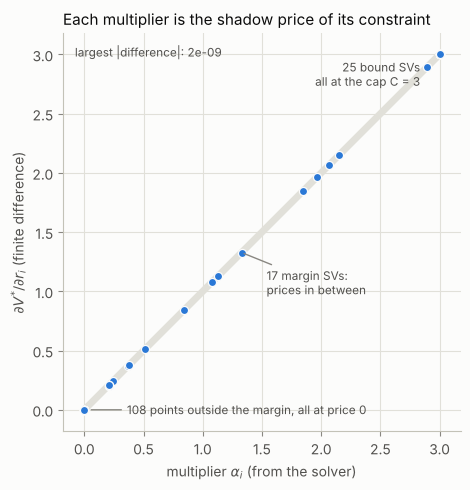

In [5]:
alpha, dV = shadow_prices(model, X, y)
cats = {"non": alpha == 0, "margin": (alpha > 0) & (alpha < model.C), "bound": alpha == model.C}
print(f"max |alpha_i - dV/dr_i| over {len(alpha)} points: {np.abs(alpha - dV).max():.1e}")

C = model.C
fig, ax = plt.subplots(figsize=(5.4, 5.0))
ax.plot([0, C], [0, C], color=GRID, lw=5, solid_capstyle="round", zorder=1)
ax.scatter(alpha, dV, s=34, color=BLUE, edgecolors=SURFACE, linewidths=0.9, zorder=3)
ax.annotate(f"{cats['non'].sum()} points outside the margin, all at price 0", (0, 0), xytext=(0.12 * C, 0),
            va="center", fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED, shrinkB=5))
ax.annotate(f"{cats['bound'].sum()} bound SVs\nall at the cap C = {C:g}", (C, C), xytext=(-14, -4),
            textcoords="offset points", ha="right", va="top", fontsize=8.5, color=INK2)
k = np.flatnonzero(cats["margin"])[np.argmin(np.abs(alpha[cats["margin"]] - 0.45 * C))]
ax.annotate(f"{cats['margin'].sum()} margin SVs:\nprices in between", (alpha[k], dV[k]), xytext=(18, -30),
            textcoords="offset points", fontsize=8.5, color=INK2, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.text(0.03, 0.97, f"largest |difference|: {np.abs(alpha - dV).max():.0e}", transform=ax.transAxes,
        va="top", fontsize=8.5, color=INK2)
ax.set(xlim=(-0.18, C + 0.18), ylim=(-0.18, C + 0.18), aspect="equal",
       xlabel="multiplier $\\alpha_i$ (from the solver)", ylabel="$\\partial V^{*} / \\partial r_i$ (finite difference)",
       title="Each multiplier is the shadow price of its constraint")
fig.tight_layout()
fig.savefig("../figures/shadow_prices.png", dpi=160)

A concrete reading: demand 5% more margin from the margin support vector with the highest price.
The first-order prediction $\alpha_i \times 0.05$ gets the rise in the optimal objective right to within
a few percent; the rest is curvature, since the price itself goes up as the constraint tightens.

In [6]:
y_pm = np.where(y == model.classes_[1], 1.0, -1.0)
K = model._kernel(X, X)
i = np.flatnonzero(cats["margin"])[np.argmax(alpha[cats["margin"]])]
r = np.ones(len(y))
V0 = smo(K, y_pm, C, tol=1e-10)[2]["dual_objective"][-1]
r[i] = 1.05
alpha_new, _, info = smo(K, y_pm, C, tol=1e-10, r=r)
print(f"point {i}: price alpha = {alpha[i]:.4f}")
print(f"predicted rise alpha * 0.05 = {alpha[i] * 0.05:.4f}")
print(f"actual rise V(1.05) - V(1)  = {info['dual_objective'][-1] - V0:.4f}")
print(f"price after tightening      = {alpha_new[i]:.4f}")

point 117: price alpha = 2.8976
predicted rise alpha * 0.05 = 0.1449
actual rise V(1.05) - V(1)  = 0.1497
price after tightening      = 3.0000
